<a href="https://colab.research.google.com/github/lindtdor/ctg-fetal-health-ml/blob/main/notebooks/CTG_week2_data_analysis_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CTG project - week 2: data analysis and baseline

Team: ING Linda, HECKEL Lutèce, JOUSSET Laureline

We want to predict the fetal state (normal, suspect or pathological) from the CTG features.
Dataset: Cardiotocography, UCI Machine Learning Repository (https://archive.ics.uci.edu/dataset/193/cardiotocography)

In [1]:
!pip install ucimlrepo

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

In [3]:
# load the dataset from UCI
ctg = fetch_ucirepo(id=193)
X = ctg.data.features
y = ctg.data.targets

df = pd.concat([X, y], axis=1)
print(df.shape)
df.head()

(2126, 23)


,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,...,Max,Nmax,Nzeros,Mode,Mean,Median,Variance,Tendency,CLASS,NSP
0,120,0.000,0.0,0.000,0.000,0.0,0.0,73,0.5,43,...,126,2,0,120,137,121,73,1,9,2
1,132,0.006,0.0,0.006,0.003,0.0,0.0,17,2.1,0,...,198,6,1,141,136,140,12,0,6,1
2,133,0.003,0.0,0.008,0.003,0.0,0.0,16,2.1,0,...,198,5,1,141,135,138,13,0,6,1
3,134,0.003,0.0,0.008,0.003,0.0,0.0,16,2.4,0,...,170,11,0,137,134,137,13,1,6,1
4,132,0.007,0.0,0.008,0.000,0.0,0.0,16,2.4,0,...,170,9,0,137,136,138,11,1,2,1


## 1. Data checks

In [4]:
# types and missing values
print(df.dtypes.value_counts())
print("missing values:", df.isna().sum().sum())

int64      15
float64     8
Name: count, dtype: int64
missing values: 0


No missing values and all columns are numbers, so we don't need imputation or encoding.

We remove the CLASS column because some of its patterns already give the answer (FS = pathological, SUSP = suspect). Keeping it would be data leakage.

In [5]:
# drop CLASS (leakage) and remove duplicated rows
df = df.drop(columns=["CLASS"])
print("duplicates:", df.duplicated().sum())

df = df.drop_duplicates()
print(df.shape)

duplicates: 13
(2113, 22)


In [6]:
# save the clean dataset
df.to_csv("ctg_clean.csv", index=False)

## 2. Exploratory data analysis

### Target distribution

NSP
1    1646
2     292
3     175
Name: count, dtype: int64
NSP
1    0.779
2    0.138
3    0.083
Name: proportion, dtype: float64


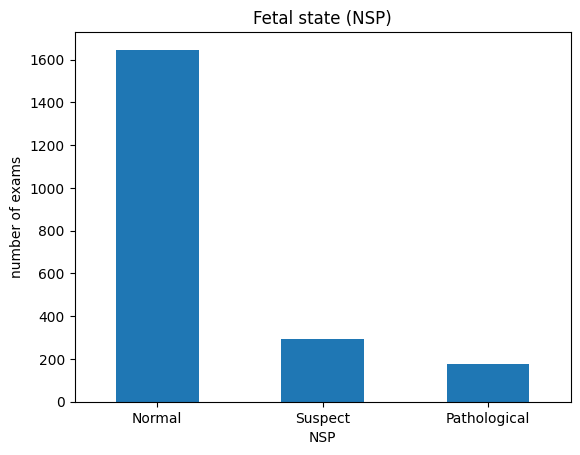

In [7]:
# separate features and target
X = df.drop(columns=["NSP"])
y = df["NSP"]

# 1 = normal, 2 = suspect, 3 = pathological
print(y.value_counts())
print(y.value_counts(normalize=True).round(3))

y.value_counts().sort_index().plot(kind="bar")
plt.xticks([0, 1, 2], ["Normal", "Suspect", "Pathological"], rotation=0)
plt.ylabel("number of exams")
plt.title("Fetal state (NSP)")
plt.show()

The classes are very imbalanced: 77.9% normal, 13.8% suspect and only 8.3% pathological. A model that always says "normal" would already have 78% accuracy, so accuracy is not a good metric here. We will mainly look at the macro-F1 and the recall of each class.

### Features

In [8]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
LB,2113.0,133.304780,9.837451,106.0,126.000,133.000,140.000,160.000
AC,2113.0,0.003188,0.003871,0.0,0.000,0.002,0.006,0.019
FM,2113.0,0.009517,0.046804,0.0,0.000,0.000,0.003,0.481
UC,2113.0,0.004387,0.002941,0.0,0.002,0.005,0.007,0.015
DL,2113.0,0.001901,0.002966,0.0,0.000,0.000,0.003,0.015
DS,2113.0,0.000003,0.000057,0.0,0.000,0.000,0.000,0.001
DP,2113.0,0.000159,0.000592,0.0,0.000,0.000,0.000,0.005
ASTV,2113.0,46.993848,17.177782,12.0,32.000,49.000,61.000,87.000
MSTV,2113.0,1.335021,0.884368,0.2,0.700,1.200,1.700,7.000
ALTV,2113.0,9.795078,18.337073,0.0,0.000,0.000,11.000,91.000


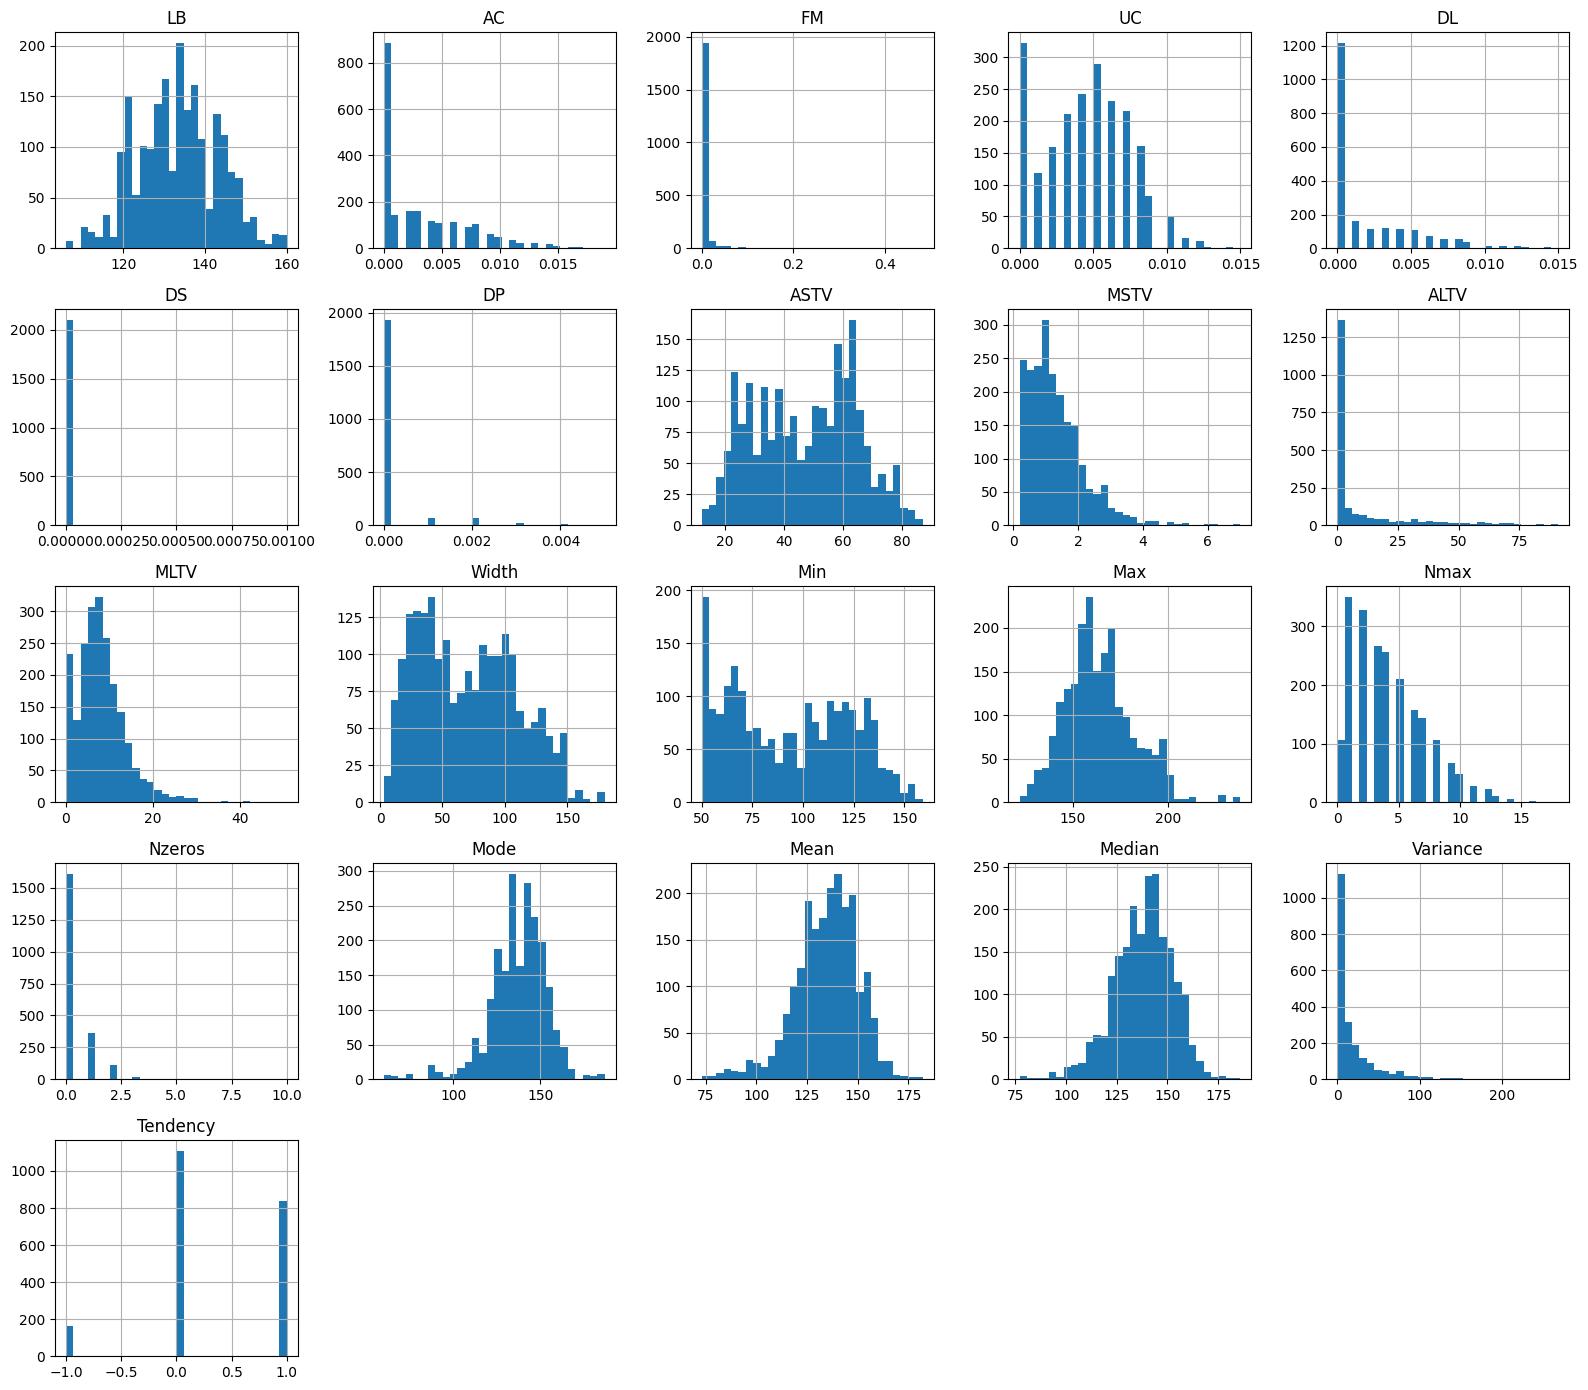

In [9]:
X.hist(bins=30, figsize=(16, 14))
plt.tight_layout()
plt.show()

In [10]:
# share of zeros for the "event" features
print((X[["AC", "FM", "UC", "DL", "DS", "DP"]] == 0).mean().round(3))
print("non zero values in DS:", (X["DS"] > 0).sum())

AC    0.419
FM    0.616
UC    0.153
DL    0.576
DS    0.997
DP    0.916
dtype: float64
non zero values in DS: 7


The features have very different scales (beats per minute, percentages, counts per second), so we need to standardize them for the logistic regression.
Some features are almost always 0: DS (severe decelerations) is non zero for only 7 exams, and DP is 0 for 92% of exams.

### Features vs fetal state

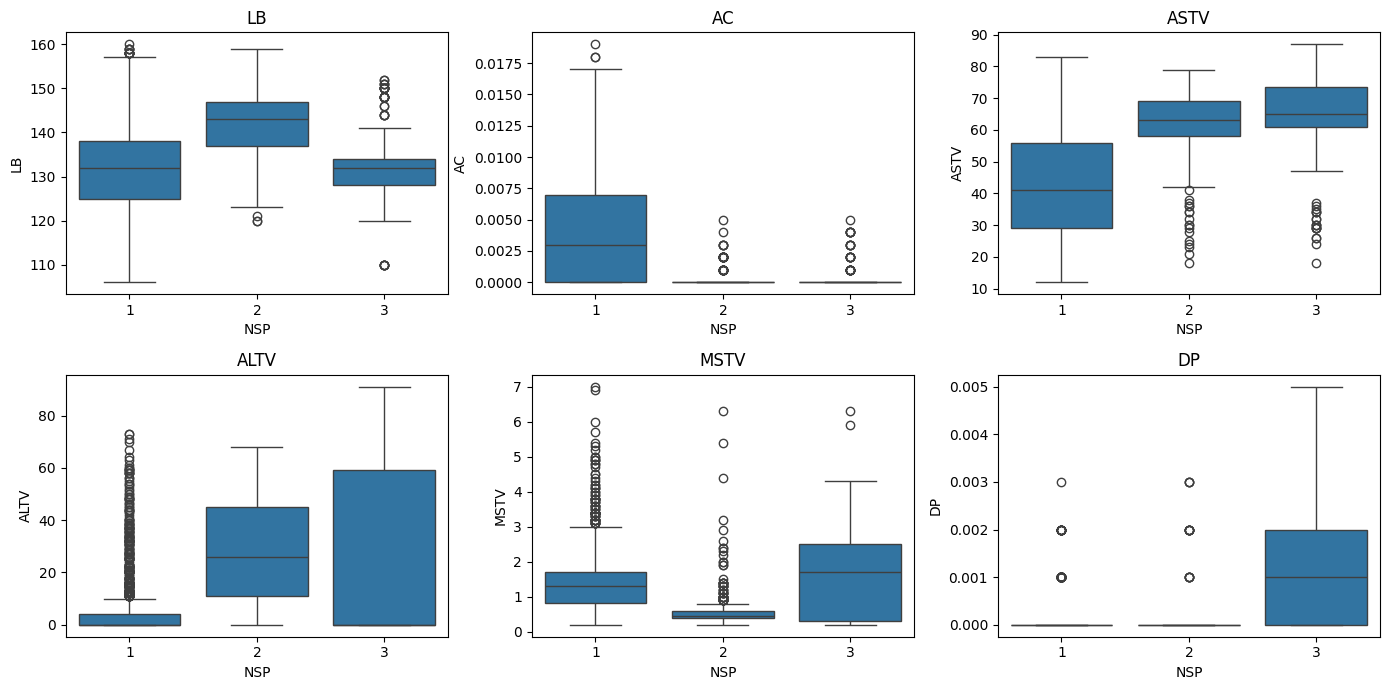

In [11]:
cols = ["LB", "AC", "ASTV", "ALTV", "MSTV", "DP"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), cols):
    sns.boxplot(x=y, y=X[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [12]:
# mean of each feature for each class
X.groupby(y).mean().T

NSP,1,2,3
LB,1.319982e+02,141.650685,131.668571
AC,4.001823e-03,0.000277,0.000394
FM,8.002430e-03,0.008284,0.025823
UC,4.800729e-03,0.002404,0.003806
DL,1.952005e-03,0.000541,0.003691
DS,6.075334e-07,0.000000,0.000034
DP,5.164034e-05,0.000096,0.001280
ASTV,4.250182e+01,61.791096,64.554286
MSTV,1.431713e+00,0.642123,1.581714
ALTV,5.059538e+00,28.832192,22.571429


- ASTV and ALTV (% of time with abnormal variability) are much higher for suspect and pathological exams.
- AC (accelerations) is higher for normal exams, which makes sense because accelerations are a good sign.
- DP (prolonged decelerations) is higher on average for pathological exams.
- Pathological exams also have a lower Mode/Mean/Median and a much higher Variance.

These features match what doctors look at on a CTG.

### Correlations

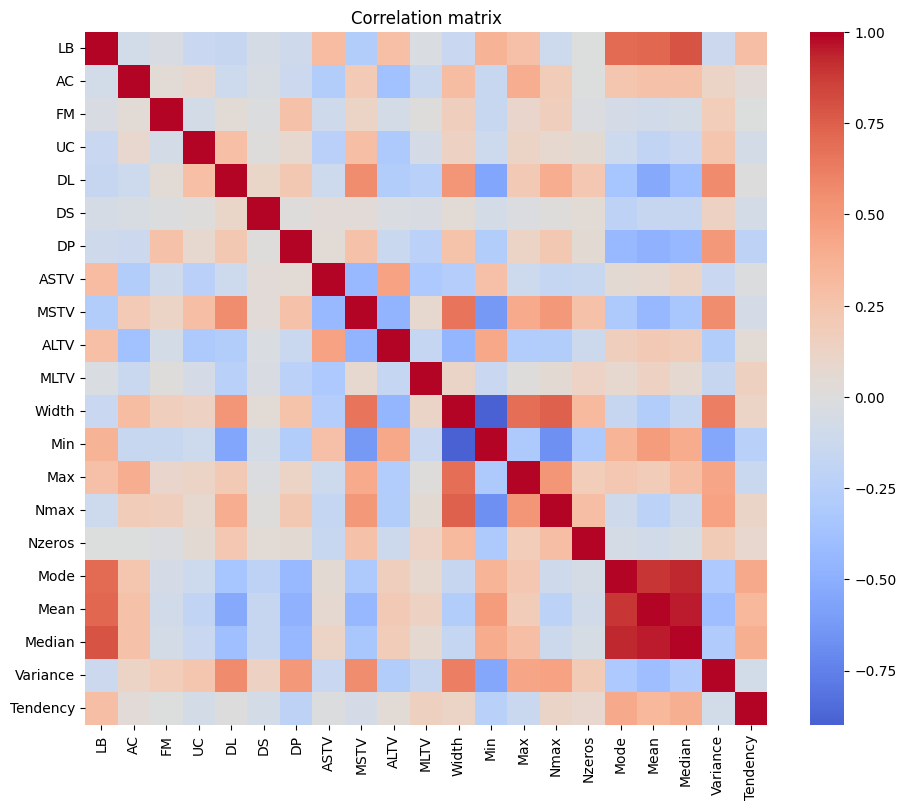

Width - Min -0.9
Mode - Mean 0.89
Mode - Median 0.93
Mean - Median 0.95


In [13]:
corr = X.corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

# pairs of features with |corr| > 0.8
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        if abs(corr.iloc[i, j]) > 0.8:
            print(corr.columns[i], "-", corr.columns[j], round(corr.iloc[i, j], 2))

Mode, Mean and Median are very correlated (0.89 to 0.95): they give almost the same information. Width and Min are also strongly anti-correlated (-0.9).
We keep the extreme values because they are real measurements and often the most important ones for pathological cases.

## 3. Train / test split

We use a stratified 80/20 split, so both sets keep the same class proportions. The test set is kept for the end of the project.

In [14]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True).round(3))
print(y_test.value_counts(normalize=True).round(3))

(1690, 21) (423, 21)
NSP
1    0.779
2    0.138
3    0.083
Name: proportion, dtype: float64
NSP
1    0.780
2    0.137
3    0.083
Name: proportion, dtype: float64


## 4. Baseline

We use 5-fold stratified cross-validation on the training set.
Main metric: macro-F1 (same weight for the 3 classes). We also look at the balanced accuracy and the recall of the pathological class.
The scaler is inside the Pipeline, so it is only fitted on the training folds (no data leakage).

In [15]:
import warnings
warnings.filterwarnings("ignore")  # hide the warnings of the dummy model

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def evaluate(model, X_tr, name):
    scores = cross_validate(model, X_tr, y_train, cv=cv, scoring=["accuracy", "f1_macro", "balanced_accuracy"])
    y_pred = cross_val_predict(model, X_tr, y_train, cv=cv)
    report = classification_report(y_train, y_pred, output_dict=True)
    return {
        "model": name,
        "accuracy": scores["test_accuracy"].mean(),
        "macro-F1": scores["test_f1_macro"].mean(),
        "balanced accuracy": scores["test_balanced_accuracy"].mean(),
        "recall pathological": report["3"]["recall"],
    }

### Dummy classifier (always predicts "normal")

In [16]:
dummy = DummyClassifier(strategy="most_frequent")
res_dummy = evaluate(dummy, X_train, "Dummy")
res_dummy

{'model': 'Dummy',
 'accuracy': np.float64(0.7786982248520709),
 'macro-F1': np.float64(0.2918605572477027),
 'balanced accuracy': np.float64(0.3333333333333333),
 'recall pathological': 0.0}

### Logistic regression

              precision    recall  f1-score   support

      Normal       0.94      0.95      0.94      1316
     Suspect       0.65      0.65      0.65       234
Pathological       0.79      0.71      0.75       140

    accuracy                           0.89      1690
   macro avg       0.79      0.77      0.78      1690
weighted avg       0.89      0.89      0.89      1690



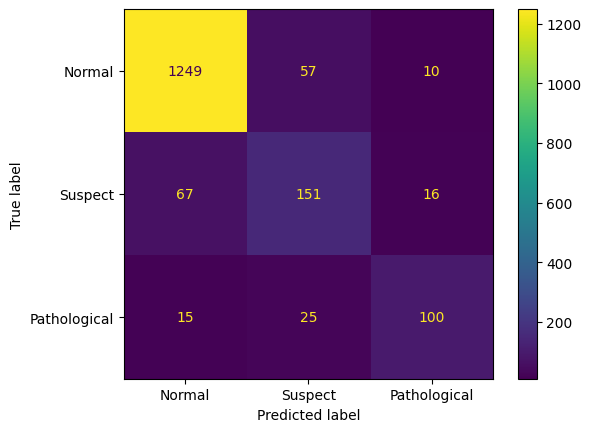

In [17]:
logreg = Pipeline([("scaler", StandardScaler()), ("model", LogisticRegression(max_iter=1000))])
res_logreg = evaluate(logreg, X_train, "Logistic regression")

y_pred = cross_val_predict(logreg, X_train, y_train, cv=cv)
print(classification_report(y_train, y_pred, target_names=["Normal", "Suspect", "Pathological"]))
ConfusionMatrixDisplay.from_predictions(y_train, y_pred, display_labels=["Normal", "Suspect", "Pathological"])
plt.show()

### Logistic regression with class weights
The classes are imbalanced, so we also try class_weight="balanced" to give more weight to the rare classes.

In [18]:
logreg_bal = Pipeline([("scaler", StandardScaler()), ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))])
res_bal = evaluate(logreg_bal, X_train, "Logistic regression (balanced)")

y_pred_bal = cross_val_predict(logreg_bal, X_train, y_train, cv=cv)
print(classification_report(y_train, y_pred_bal, target_names=["Normal", "Suspect", "Pathological"]))

              precision    recall  f1-score   support

      Normal       0.99      0.87      0.93      1316
     Suspect       0.56      0.83      0.67       234
Pathological       0.67      0.85      0.75       140

    accuracy                           0.86      1690
   macro avg       0.74      0.85      0.78      1690
weighted avg       0.90      0.86      0.87      1690



## 5. Features we keep

Mean and Mode are very correlated with Median (0.89 to 0.95), so they give almost the same information. DS is non zero for only 7 exams.
We test the logistic regression without these 3 features (18 features left).

In [19]:
to_drop = ["Mean", "Mode", "DS"]
res_18 = evaluate(logreg, X_train.drop(columns=to_drop), "Logistic regression (18 features)")
res_18_bal = evaluate(logreg_bal, X_train.drop(columns=to_drop), "Logistic regression balanced (18 features)")

results = pd.DataFrame([res_dummy, res_logreg, res_bal, res_18, res_18_bal]).set_index("model").round(3)
results

,accuracy,macro-F1,balanced accuracy,recall pathological
model,,,,
Dummy,0.779,0.292,0.333,0.000
Logistic regression,0.888,0.779,0.769,0.714
Logistic regression (balanced),0.864,0.781,0.850,0.850
Logistic regression (18 features),0.893,0.792,0.780,0.750
Logistic regression balanced (18 features),0.860,0.776,0.846,0.843


Removing Mean, Mode and DS does not make the results worse (macro-F1 around 0.78-0.79 in both cases), so we keep the 18 features: the model is simpler and has less redundant information.

In [20]:
# save the final clean dataset (18 features + target)
df_final = df.drop(columns=to_drop)
df_final.to_csv("ctg_clean.csv", index=False)
print(df_final.shape)

(2113, 19)


## 6. Conclusion and next steps

- The data is clean: no missing values, 13 duplicates removed, CLASS removed (leakage). We keep 18 features.
- The classes are very imbalanced, so we use macro-F1 and recall instead of accuracy.
- The dummy model gets 78% accuracy but only 0.29 macro-F1. The logistic regression is much better (macro-F1 around 0.78). With class weights, the recall of the pathological class goes up to about 0.85, which is important for a medical tool.

Next week: other models (kNN, decision tree, random forest, SVM), hyperparameter tuning, feature selection methods, and comparison with this baseline.